In [1]:
# Je vérifie juste que ma clé secrète est bien chargée depuis le .env, sans l'afficher.
import os
print("Clé chargée :", os.environ.get("PSEUDO_KEY") is not None)

Clé chargée : True


In [2]:
# Je crée ma fonction de pseudonymisation avec HMAC-SHA256 et ma clé secrète,
# je charge les commandes depuis MongoDB et j'ajoute la colonne user_id_pseudo.
import os, hmac, hashlib
import pandas as pd
from pymongo import MongoClient

CLE = os.environ["PSEUDO_KEY"].encode()

def pseudonymiser(identifiant):
    return hmac.new(CLE, str(identifiant).encode(), hashlib.sha256).hexdigest()

db = MongoClient()["commerce"]
commandes = pd.DataFrame(list(db["raw_commandes"].find({}, {"_id": 0})))

commandes["user_id_pseudo"] = commandes["user_id"].apply(pseudonymiser)

commandes[["user_id", "user_id_pseudo"]].drop_duplicates().head()

,user_id,user_id_pseudo
0,1,088d1b3dcab3b5d06446d8d9e42fe5c919d71eb0cb1add...
4,2,a0b4a5a28ed51a8ebad8442ce81807dabd4ef575f36688...
6,3,5b626e50f34c4d29368b946e69f73a7f3a689ac89bc8a8...
12,4,9f173d0c18c88570fec2d109d828810cc44b82455579d5...
14,5,5884d3eedfb4335d98991156dd1581dd67d86ae9dc3de7...


In [3]:
# Je vérifie que chaque client a un seul pseudonyme et que je peux toujours faire des totaux par client.
# Ensuite je pseudonymise aussi les paiements et je vérifie que les pseudonymes sont les mêmes des deux côtés.
nb_pseudos = commandes.groupby("user_id")["user_id_pseudo"].nunique()
print("Clients avec plus d'un pseudonyme :", (nb_pseudos > 1).sum())

print(commandes.groupby("user_id_pseudo")["discounted_line_total"].sum().round(2).head())

paiements = pd.DataFrame(list(db["raw_payments"].find({}, {"_id": 0})))
paiements["user_id_pseudo"] = paiements["user_id"].apply(pseudonymiser)

comparaison = (commandes[["user_id", "user_id_pseudo"]].drop_duplicates()
    .merge(paiements[["user_id", "user_id_pseudo"]], on="user_id", suffixes=("_cmd", "_pay")))
print("Clients comparés :", len(comparaison))
print("Pseudonymes identiques partout :", (comparaison["user_id_pseudo_cmd"] == comparaison["user_id_pseudo_pay"]).all())

Clients avec plus d'un pseudonyme : 0
user_id_pseudo
005329421cf369d7d30544fc74c52ae9494ffac0ff7e083eec8191f2d4cb81ca    20510.13
04a5bae7ca8245d6530f9ec956a8aad1fd25a658fd62b749600c73550e6f6d4e      213.26
06aa0e98910c1caf383eca5c226a71acaa7298019881a558a97780f001942b8a     2168.95
071e3ae851a3787ef81cd2477b8e6ee44ed2bb82938666b0460f8e395fa3f631    15464.38
088d1b3dcab3b5d06446d8d9e42fe5c919d71eb0cb1adde25ff9f1bc44f1bd90    11510.81
Name: discounted_line_total, dtype: float64
Clients comparés : 208
Pseudonymes identiques partout : True


# Réponses – Atelier 1 : pseudonymisation

### 1. Identifiants avant / après

Voir le tableau ci-dessus (`user_id` → `user_id_pseudo`).

### 2. Pourquoi un même client garde le même pseudonyme ?

HMAC fonctionne de manière déterministe : avec le même identifiant et la même clé, on obtient toujours le même résultat.
Cela permet donc de conserver le même pseudonyme pour un client dans toutes ses commandes et ses paiements, à condition d'utiliser la même clé partout.
C'est important pour pouvoir continuer à regrouper les données et faire des liens entre les différents datasets.
On a vérifié que cela fonctionnait bien : aucun client n'avait plusieurs pseudonymes et les pseudonymes étaient identiques pour les 208 clients entre les commandes et les paiements.

### 3. Pourquoi la clé ne doit pas être déposée sur GitHub ?

Si quelqu'un récupère la clé, il peut recalculer les pseudonymes à partir des identifiants d'origine (de 1 à 208) et retrouver à quel client correspond chaque pseudonyme.
La pseudonymisation ne servirait alors plus à protéger les données.
C'est pour cette raison que la clé est stockée dans un fichier `.env`, qui est exclu du dépôt GitHub grâce au `.gitignore`. Elle n'est également jamais affichée directement dans le notebook.

### 4. Limites de la pseudonymisation et précautions

La pseudonymisation ne signifie pas que les données sont totalement anonymes. Il reste possible de retrouver l'identité d'un client si on possède la clé ou si on croise certaines informations, comme les montants, les dates ou les produits achetés.
Les données restent donc considérées comme personnelles au sens du RGPD et doivent être protégées.
Pour limiter les risques, il faut notamment :
- Limiter l'accès aux datasets.
- Ne pas diffuser les données publiquement.
- Conserver la clé séparément des données.
- Supprimer les identifiants directs (`user_id`, `username`) avant l'export.

In [4]:
# Je nettoie les montants et les dates, et je recrée payment_date avec la première date du panier.
# J'enlève les identifiants directs et je pseudonymise aussi cart_id (sinon on pourrait retrouver le client),
# puis j'exporte les commandes et les paiements en Parquet.
commandes["discounted_line_total"] = pd.to_numeric(commandes["discounted_line_total"], errors="coerce")
commandes["order_date"] = pd.to_datetime(commandes["order_date"], errors="coerce")
commandes = commandes.dropna(subset=["discounted_line_total", "order_date"])

paiements = paiements.rename(columns={"status": "payment_status"})
paiements["amount"] = pd.to_numeric(paiements["amount"], errors="coerce")

dates_paniers = commandes.groupby("cart_id")["order_date"].min().rename("payment_date")
paiements = paiements.merge(dates_paniers, on="cart_id", how="left")
paiements = paiements.dropna(subset=["amount", "payment_date"])

commandes_pseudo = commandes.drop(columns=["user_id", "username"])
paiements_pseudo = paiements.drop(columns=["user_id"])

def pseudonymiser_panier(cart_id):
    return pseudonymiser("cart-" + str(cart_id))

commandes_pseudo["cart_id_pseudo"] = commandes_pseudo["cart_id"].apply(pseudonymiser_panier)
paiements_pseudo["cart_id_pseudo"] = paiements_pseudo["cart_id"].apply(pseudonymiser_panier)

commandes_pseudo = commandes_pseudo.drop(columns=["cart_id", "order_id"])
paiements_pseudo = paiements_pseudo.drop(columns=["cart_id"])

os.makedirs("data", exist_ok=True)
commandes_pseudo.to_parquet("data/commandes_pseudo.parquet", index=False)
paiements_pseudo.to_parquet("data/paiements_pseudo.parquet", index=False)

print("Commandes :", commandes_pseudo.shape, "| Paiements :", paiements_pseudo.shape)
print("Colonnes paiements :", list(paiements_pseudo.columns))

Commandes : (800, 14) | Paiements : (208, 5)
Colonnes paiements : ['amount', 'payment_status', 'user_id_pseudo', 'payment_date', 'cart_id_pseudo']


### Correction d'une faille de réidentification

Lors de nos vérifications, on a remarqué que `cart_id` correspondait exactement à `user_id` pour tous les paniers. Cela s'explique par le fait que chaque utilisateur DummyJSON ne possède qu'un seul panier.
Le problème, c'est qu'en conservant `cart_id` ou `order_id` (par exemple `CART-00001`) dans nos datasets, il aurait été possible de retrouver directement l'identifiant réel du client et donc de contourner la pseudonymisation.
Pour corriger cette faille, on a également pseudonymisé `cart_id` avec HMAC, en utilisant le préfixe `cart-` afin que le pseudonyme du panier soit différent de celui du client. On a ensuite supprimé `cart_id` et `order_id` avant l'export au format Parquet.
Cette correction montre qu'il ne suffit pas de remplacer les identifiants principaux pour protéger les données. Il faut aussi vérifier les autres champs qui pourraient permettre de retrouver l'identité d'un client en croisant plusieurs informations.

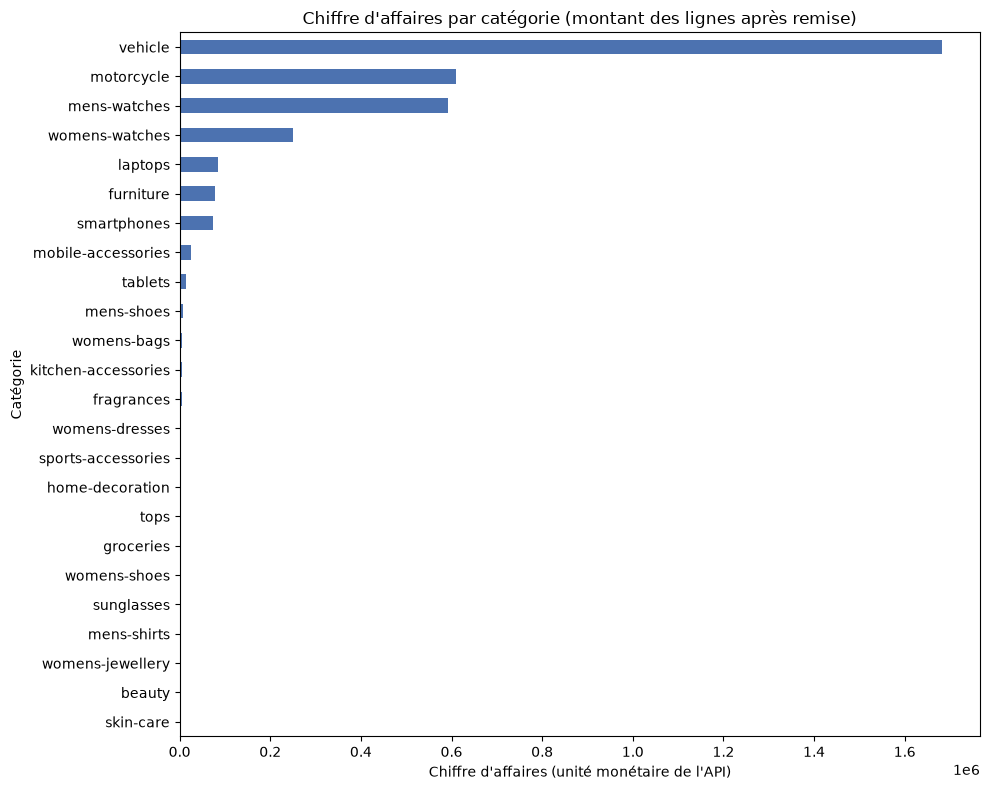

In [5]:
# Graphique 1 : le CA par catégorie en barres horizontales, que j'enregistre aussi en PNG dans resultats/.
import matplotlib.pyplot as plt

os.makedirs("resultats", exist_ok=True)

ca = commandes_pseudo.groupby("category")["discounted_line_total"].sum().sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
ca.plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Chiffre d'affaires par catégorie (montant des lignes après remise)")
ax.set_xlabel("Chiffre d'affaires (unité monétaire de l'API)")
ax.set_ylabel("Catégorie")
plt.tight_layout()
plt.savefig("resultats/ca_par_categorie.png", dpi=150)
plt.show()

### Interprétation – CA par catégorie

On remarque que le chiffre d'affaires est surtout réparti sur quelques catégories. La catégorie `vehicle` représente à elle seule environ 49 % du chiffre d'affaires total. Si on ajoute `motorcycle` et `mens-watches`, les trois premières catégories représentent environ 83 % du total.
Les autres catégories ont une part beaucoup plus faible et sont presque invisibles sur le graphique.
Cela montre que notre chiffre d'affaires dépend beaucoup de quelques catégories de produits assez chers. Si les ventes de l'une de ces catégories diminuent, cela pourrait avoir un impact important sur le chiffre d'affaires global.
À l'inverse, certaines catégories comme `groceries` ou `kitchen-accessories` sont plus fréquentes, mais rapportent finalement beaucoup moins.

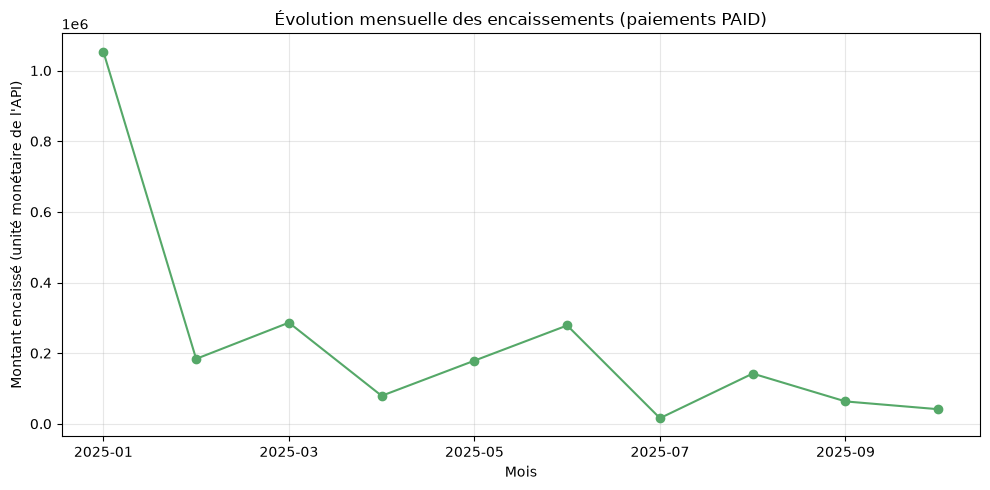

In [6]:
# Graphique 2 : je garde les paiements PAID et je fais la somme par mois pour tracer la courbe des encaissements.
paid = paiements_pseudo[paiements_pseudo["payment_status"] == "PAID"]

mensuel = paid.groupby(paid["payment_date"].dt.to_period("M"))["amount"].sum()
mensuel.index = mensuel.index.astype(str)

fig, ax = plt.subplots(figsize=(10, 5))
mensuel.plot(ax=ax, marker="o", color="#55A868")
ax.set_title("Évolution mensuelle des encaissements (paiements PAID)")
ax.set_xlabel("Mois")
ax.set_ylabel("Montant encaissé (unité monétaire de l'API)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("resultats/evolution_mensuelle.png", dpi=150)
plt.show()

### Interprétation – Évolution mensuelle des encaissements

On remarque une forte baisse des encaissements au fil des mois. On passe de plus d'un million en janvier à seulement quelques dizaines de milliers en fin d'année. On constate également qu'il n'y a aucun paiement en novembre et décembre.
Cependant, cette baisse ne correspond pas à une réelle évolution des ventes. Le problème vient de la façon dont la date `payment_date` a été créée : elle correspond à la première date des différentes lignes du panier. Comme les dates sont générées aléatoirement, la date la plus ancienne tombe généralement en début d'année.
On ne peut donc pas utiliser ce graphique pour tirer des conclusions sur une éventuelle saisonnalité des ventes.
Cela montre qu'il faut bien vérifier l'origine et la construction des données avant d'interpréter les résultats d'un graphique, car ils peuvent être trompeurs.

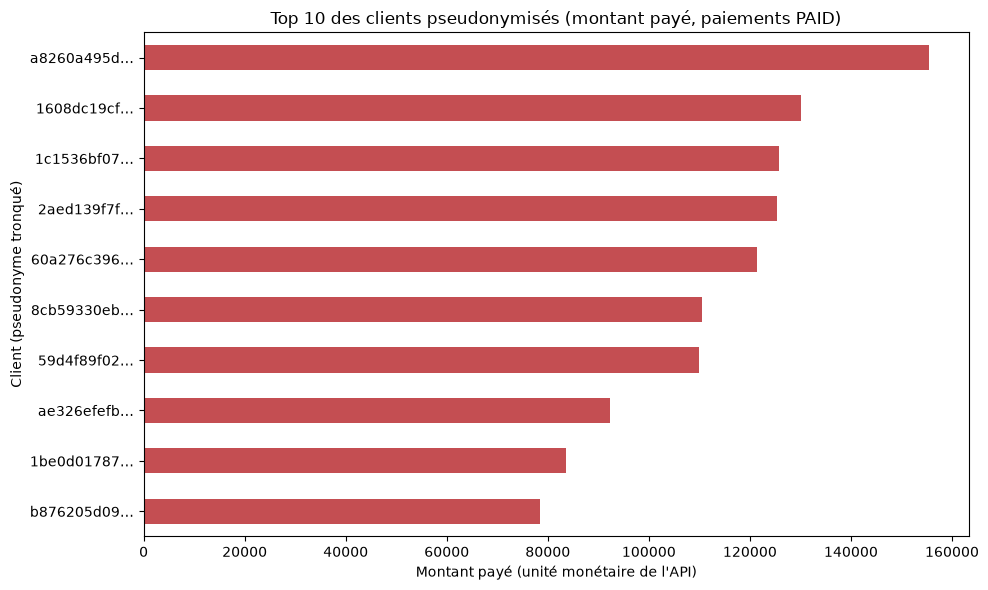

In [7]:
# Graphique 3 : le top 10 des clients pseudonymisés. Je n'affiche que le début du pseudonyme pour que ce soit lisible.
top10 = paid.groupby("user_id_pseudo")["amount"].sum().nlargest(10).sort_values()
top10.index = top10.index.str[:10] + "…"

fig, ax = plt.subplots(figsize=(10, 6))
top10.plot.barh(ax=ax, color="#C44E52")
ax.set_title("Top 10 des clients pseudonymisés (montant payé, paiements PAID)")
ax.set_xlabel("Montant payé (unité monétaire de l'API)")
ax.set_ylabel("Client (pseudonyme tronqué)")
plt.tight_layout()
plt.savefig("resultats/top10_clients.png", dpi=150)
plt.show()

### Interprétation – Top 10 des clients pseudonymisés

On remarque que les 10 premiers clients représentent environ 1,13 million, soit presque 49 % du montant total encaissé. Pourtant, ils représentent moins de 7 % des 145 clients ayant effectué un paiement.
Cela montre qu'une grande partie du chiffre d'affaires repose sur un petit nombre de clients. Il pourrait donc être intéressant de mettre en place des actions pour les fidéliser.
La pseudonymisation permet de réaliser cette analyse sans avoir besoin d'afficher les véritables identifiants des clients.
Il faut tout de même prendre en compte une limite : chaque client n'ayant qu'un seul panier, ce classement met surtout en avant les clients ayant effectué les achats les plus importants, et ne permet pas vraiment d'identifier les clients les plus fidèles.